# 04 · Churn model: baselines, calibration, explanations

**Pipeline:** bronze → silver → gold features → **churn model** → ARR forecast → retention playbook

**Evaluation design**
* **Temporal split:** train on everything before the calibration window, fit the probability calibrator
  on the next 3 months, test on the final 3 labelled months. No customer-month from the future is used.
  Hyper-parameters were chosen on the calibration window, never on the test window.
* **Metrics for a ~2% base rate:** PR-AUC, precision/recall when contacting the top 10% of accounts,
  share of *churned ARR* captured, and calibration (Brier score, predicted vs. actual churners).
  ROC-AUC is reported but is flattering on imbalanced data.
* **Baselines:** a rule of thumb ("logins fell 30%+ below the customer's own average") and logistic
  regression. The boosted model has to beat both to justify itself.
* **Calibration matters here** because the output is used as a probability: ARR at risk =
  P(churn) × ARR, and the Monte Carlo forecast uses it as a hazard. `scale_pos_weight` helps the trees
  learn rare churners but inflates raw scores roughly by a constant factor in odds, so they are mapped
  back with **Platt scaling** (a logistic fit on the raw log-odds). It is strictly monotone, so ranking
  is untouched. Isotonic regression was tried first: its step function created large blocks of tied
  scores (hurting PR-AUC) and pushed some accounts to exactly 100%.

Runs are logged to MLflow (params, metrics, charts, model).

In [1]:
%pip install -q -r ../requirements.txt

In [2]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
from revenue_pipeline import config, spark_utils

spark = spark_utils.get_spark()
print(f"Spark {spark.version} | schema: {config.SCHEMA} | Databricks: {spark_utils.on_databricks()}")

Spark 3.5.3 | schema: revenue_forecasting | Databricks: False


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from revenue_pipeline import modeling, charts

charts.apply_style()
feat = spark.table("gold_customer_features").toPandas()
feat["month"] = pd.to_datetime(feat["month"])

labelled_months = sorted(modeling.labelled(feat)["month"].unique())
test_start = labelled_months[-config.TEST_MONTHS]
last_train_month = modeling.month_offset(test_start, -1)

data = modeling.labelled(feat)
train = data[data["month"] <= last_train_month]
test = data[data["month"] >= test_start]
print(f"Train+calibration: {train['month'].min():%Y-%m} → {last_train_month:%Y-%m}  ({len(train):,} rows)")
print(f"Test:              {test_start:%Y-%m} → {test['month'].max():%Y-%m}  ({len(test):,} rows, "
      f"churn rate {test['churn_next_month'].mean():.2%})")

Train+calibration: 2022-01 → 2024-08  (104,083 rows)
Test:              2024-09 → 2024-11  (22,479 rows, churn rate 1.44%)


In [4]:
xgb_model = modeling.fit_churn_model(feat, last_train_month)
logit = modeling.fit_logistic(train)

y_test, arr_test = test["churn_next_month"].astype(int), test["arr"]
scores = {
    "Rule: logins below own average": modeling.login_drop_score(test),
    "Logistic regression": logit.predict_proba(modeling.prepare_features(test))[:, 1],
    "XGBoost (raw, class-weighted)": xgb_model.predict_raw(test),
    "XGBoost + Platt calibration": xgb_model.predict_proba(test),
}
metrics = pd.DataFrame({name: modeling.evaluate(y_test, p, arr_test) for name, p in scores.items()}).T
# The rule's score is not a probability, so its calibration metrics are meaningless.
metrics.loc["Rule: logins below own average", ["brier", "log_loss", "predicted_churners"]] = np.nan
print(metrics.round(4).to_string())

rule = modeling.flag_metrics(y_test, modeling.login_drop_flag(test))
print(f"\nBinary rule (logins < 70% of own average): flags {rule['flagged_share']:.1%} of accounts, "
      f"precision {rule['precision']:.1%}, recall {rule['recall']:.1%}")

                                roc_auc  pr_auc   brier  log_loss  precision_top10  recall_top10  churned_arr_captured_top10  predicted_churners  actual_churners
Rule: logins below own average   0.6207  0.0285     NaN       NaN           0.0369        0.2562                      0.2464                 NaN            324.0
Logistic regression              0.7947  0.1018  0.0136    0.0647           0.0601        0.4167                      0.4053            333.1402            324.0
XGBoost (raw, class-weighted)    0.7982  0.1076  0.2053    0.5525           0.0601        0.4167                      0.4295           8413.1299            324.0
XGBoost + Platt calibration      0.7982  0.1076  0.0135    0.0642           0.0601        0.4167                      0.4295            315.1791            324.0

Binary rule (logins < 70% of own average): flags 16.7% of accounts, precision 3.0%, recall 34.6%


### Calibration: raw class-weighted scores vs. Platt-calibrated probabilities

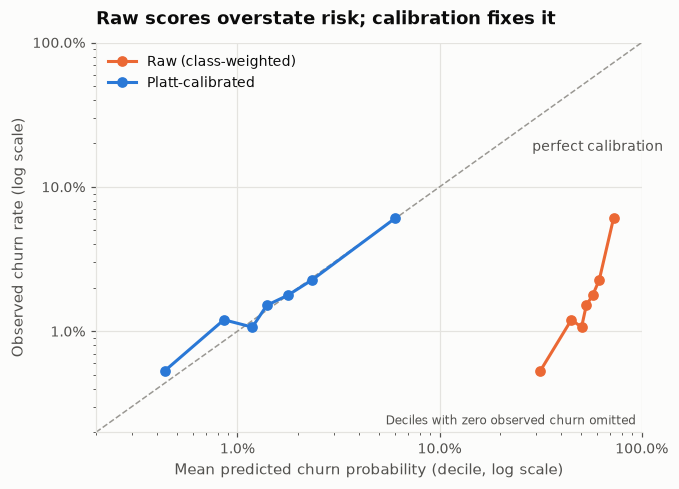

In [5]:
# Log axes can't show deciles with zero observed churn (annual contracts between renewals), so drop them.
raw_cal = modeling.calibration_table(y_test, scores["XGBoost (raw, class-weighted)"]).query("observed_rate > 0")
iso_cal = modeling.calibration_table(y_test, scores["XGBoost + Platt calibration"]).query("observed_rate > 0")

fig, ax = plt.subplots(figsize=(6.4, 4.6))
lo, hi = 0.002, 1.0
ax.plot([lo, hi], [lo, hi], color=charts.REFERENCE, lw=1, ls="--")
ax.plot(raw_cal["mean_predicted"], raw_cal["observed_rate"], "o-", color=charts.SERIES[1], ms=6, label="Raw (class-weighted)")
ax.plot(iso_cal["mean_predicted"], iso_cal["observed_rate"], "o-", color=charts.SERIES[0], ms=6, label="Platt-calibrated")
ax.annotate("perfect calibration", (0.25, 0.25), xytext=(8, -14), textcoords="offset points",
            color=charts.C["text_muted"], fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
charts.percent(ax, "x", 1); charts.percent(ax, "y", 1)
ax.grid(axis="x", visible=True)
ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="Mean predicted churn probability (decile, log scale)",
       ylabel="Observed churn rate (log scale)")
ax.text(0.99, 0.02, "Deciles with zero observed churn omitted", transform=ax.transAxes, ha="right",
        fontsize=8, color=charts.C["text_muted"])
ax.set_title("Raw scores overstate risk; calibration fixes it")
ax.legend(loc="upper left")
charts.save(fig, "calibration.png"); plt.show()

### Capture curve: how much churn is caught by contacting the riskiest accounts first

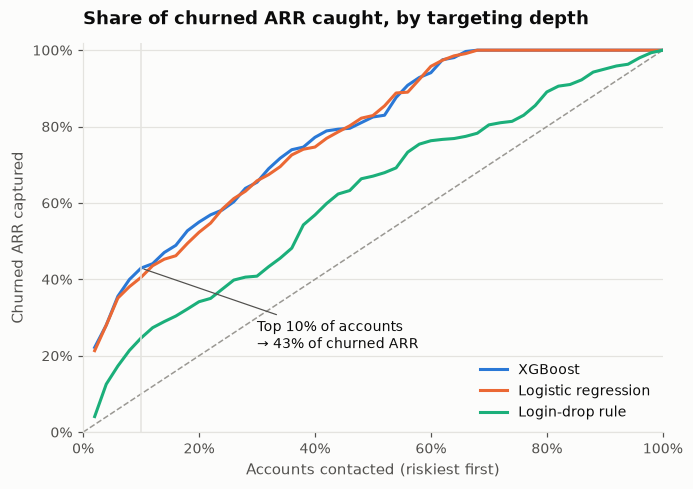

In [6]:
fig, ax = plt.subplots(figsize=(6.8, 4.6))
ax.plot([0, 1], [0, 1], color=charts.REFERENCE, lw=1, ls="--")
plotted = [("XGBoost + Platt calibration", "XGBoost"), ("Logistic regression", "Logistic regression"),
           ("Rule: logins below own average", "Login-drop rule")]
capture = []
for (key, label), color in zip(plotted, charts.SERIES):
    curve = modeling.capture_curve(y_test, scores[key], arr_test)
    capture.append(curve.assign(model=label))
    ax.plot(curve["pct_targeted"], curve["churned_arr_captured"], color=color, label=label)
ax.axvline(0.10, color=charts.C["grid"], lw=1)
top10 = metrics.loc["XGBoost + Platt calibration", "churned_arr_captured_top10"]
ax.annotate(f"Top 10% of accounts\n→ {top10:.0%} of churned ARR", (0.10, top10), xytext=(0.30, 0.22),
            textcoords="data", fontsize=9, arrowprops=dict(arrowstyle="-", color=charts.C["text_muted"], lw=0.8))
charts.percent(ax, "x"); charts.percent(ax, "y")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="Accounts contacted (riskiest first)", ylabel="Churned ARR captured")
ax.set_title("Share of churned ARR caught, by targeting depth")
ax.legend(loc="lower right")
charts.save(fig, "capture_curve.png"); plt.show()
capture = pd.concat(capture, ignore_index=True)

### What drives risk (mean |SHAP|, test set)

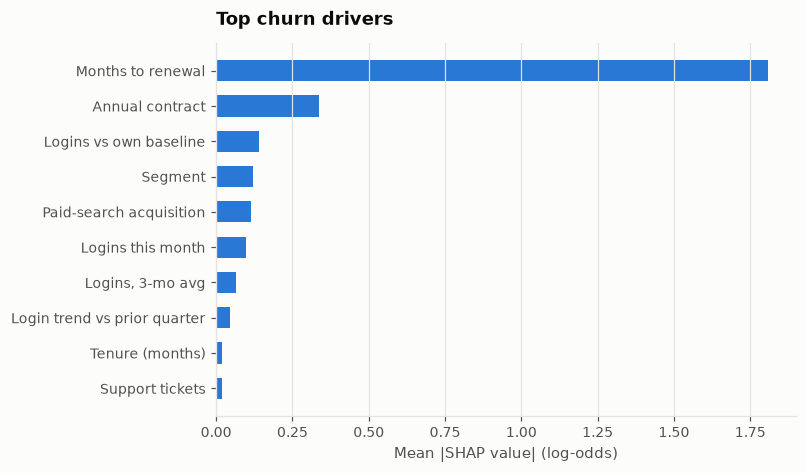

In [7]:
contrib = modeling.shap_values(xgb_model, test)
importance = contrib.abs().mean().sort_values().tail(10).rename(modeling.FEATURE_LABELS)

fig, ax = plt.subplots(figsize=(6.8, 4.4))
ax.barh(importance.index, importance.values, color=charts.SERIES[0], height=0.6)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Mean |SHAP value| (log-odds)")
ax.set_title("Top churn drivers")
charts.save(fig, "shap_importance.png"); plt.show()

### Final model and current risk snapshot

Refit on every labelled month (calibrating on the most recent three), then score the latest month.

The model predicts churn **next month**, but retention and planning decisions work on a year. The
**12-month churn probability** chains the monthly hazards from the same projection the ARR forecast
uses (tenure and renewal timing roll forward; today's signal fades toward the base rate):
P(churn within 12 months) = 1 − ∏ₕ (1 − hazardₕ). `churn_probability` / `revenue_risk` in the gold
table are the 12-month figures; the `*_next_month` columns hold the model's direct output.

Each account gets its three strongest SHAP-based reasons so the list is actionable for CSMs.

In [8]:
final_model = modeling.fit_churn_model(feat, labelled_months[-1])
snapshot = feat[feat["month"] == feat["month"].max()].reset_index(drop=True)
hazards = modeling.project_hazards(final_model, snapshot, modeling.base_rates(feat), config.FORECAST_HORIZON)

snapshot["churn_probability_next_month"] = hazards[:, 0]
snapshot["revenue_risk_next_month"] = snapshot["churn_probability_next_month"] * snapshot["arr"]
snapshot["churn_probability"] = 1 - np.prod(1 - hazards, axis=1)
snapshot["revenue_risk"] = snapshot["churn_probability"] * snapshot["arr"]
snapshot = snapshot.join(modeling.top_reasons(snapshot, modeling.shap_values(final_model, snapshot)))
snapshot["risk_tier"] = pd.cut(snapshot["revenue_risk"].rank(pct=True), [0, 0.7, 0.9, 1.0],
                               labels=["Low", "Medium", "High"]).astype(str)

risk_cols = ["customer_id", "segment", "plan_type", "arr", "churn_probability", "revenue_risk",
             "churn_probability_next_month", "revenue_risk_next_month",
             "acquisition_channel", "contract_type", "months_to_renewal", "risk_tier",
             "reason_1", "reason_2", "reason_3"]
risk = snapshot[risk_cols].sort_values("revenue_risk", ascending=False).reset_index(drop=True)

total_arr, at_risk, at_risk_1m = risk["arr"].sum(), risk["revenue_risk"].sum(), risk["revenue_risk_next_month"].sum()
print(f"Snapshot {feat['month'].max():%b %Y}: {len(risk):,} customers | ARR ${total_arr:,.0f}")
print(f"ARR at risk over the next 12 months: ${at_risk:,.0f} ({at_risk / total_arr:.1%})")
print(f"ARR at risk next month:              ${at_risk_1m:,.0f} ({at_risk_1m / total_arr:.2%})")
print(risk.drop(columns=["churn_probability_next_month", "revenue_risk_next_month"]).head(8).round(3).to_string(index=False))

Snapshot Dec 2024: 8,170 customers | ARR $35,910,348
ARR at risk over the next 12 months: $5,009,802 (14.0%)
ARR at risk next month:              $422,492 (1.18%)
 customer_id    segment  plan_type      arr  churn_probability  revenue_risk acquisition_channel contract_type  months_to_renewal risk_tier                   reason_1                reason_2                        reason_3
        6014        SMB Enterprise 10479.24              0.428      4486.958             Organic        Annual                  2      High Annual renewal in 2 months  Logins at 29% of usual Low 3-month usage (5 logins/mo)
        6239        SMB Enterprise 11988.00              0.324      3878.127             Organic       Monthly                  1      High     Logins at 36% of usual Month-to-month contract Low 3-month usage (3 logins/mo)
        5057        SMB Enterprise 11988.00              0.313      3750.955             Organic       Monthly                  1      High     Logins at 18% of usual M

In [9]:
def risk_summary(df, by):
    out = df.groupby(by).agg(customers=("customer_id", "count"), total_arr=("arr", "sum"),
                             arr_at_risk=("revenue_risk", "sum"), avg_churn=("churn_probability", "mean"),
                             arr_at_risk_next_month=("revenue_risk_next_month", "sum")).reset_index()
    out["pct_at_risk"] = out["arr_at_risk"] / out["total_arr"]
    out["share_of_total_risk"] = out["arr_at_risk"] / out["arr_at_risk"].sum()
    out["share_of_total_arr"] = out["total_arr"] / out["total_arr"].sum()
    return out.sort_values("arr_at_risk", ascending=False)

by_segment, by_plan = risk_summary(risk, "segment"), risk_summary(risk, "plan_type")
print(by_segment.round(3).to_string(index=False)); print(); print(by_plan.round(3).to_string(index=False))

metrics_out = metrics.reset_index().rename(columns={"index": "model"})
for name, df in {"gold_revenue_risk": risk, "gold_risk_by_segment": by_segment, "gold_risk_by_plan": by_plan,
                 "gold_model_metrics": metrics_out, "gold_capture_curve": capture}.items():
    spark_utils.write_table(spark, df, name)
    spark_utils.export_csv(spark, name)
print("Gold risk tables written and exported to data/gold/")

   segment  customers   total_arr  arr_at_risk  avg_churn  arr_at_risk_next_month  pct_at_risk  share_of_total_risk  share_of_total_arr
       SMB       4963 13800036.96  3033940.958      0.225              273725.441        0.220                0.606               0.384
Mid-Market       2266 12644578.44  1430165.069      0.116              108295.530        0.113                0.285               0.352
Enterprise        941  9465732.48   545695.996      0.059               40470.775        0.058                0.109               0.264

 plan_type  customers   total_arr  arr_at_risk  avg_churn  arr_at_risk_next_month  pct_at_risk  share_of_total_risk  share_of_total_arr
Enterprise       1641 20385111.12  2198022.463      0.109              163283.878        0.108                0.439               0.568
       Pro       3126 11449885.32  1951653.629      0.172              175883.019        0.170                0.390               0.319
     Basic       3403  4075351.44   860125.931 

Gold risk tables written and exported to data/gold/


In [10]:
import joblib, tempfile
mlflow = spark_utils.setup_mlflow()

with mlflow.start_run(run_name="churn_model") as run:
    mlflow.set_tag("stage", "churn_model")
    mlflow.log_params({**config.XGB_PARAMS, "features": ",".join(config.FEATURES),
                       "test_start": f"{test_start:%Y-%m}", "calibration_months": config.CALIBRATION_MONTHS})
    for model_name, row in metrics.iterrows():
        prefix = {"Rule: logins below own average": "rule", "Logistic regression": "logit",
                  "XGBoost (raw, class-weighted)": "xgb_raw", "XGBoost + Platt calibration": "xgb_cal"}[model_name]
        mlflow.log_metrics({f"{prefix}_{k}": float(v) for k, v in row.items() if pd.notna(v)})
    mlflow.log_metrics({"arr_at_risk_12m": float(at_risk), "arr_at_risk_next_month": float(at_risk_1m)})
    for img in ["calibration.png", "capture_curve.png", "shap_importance.png"]:
        mlflow.log_artifact(str(config.IMAGES_DIR / img), "charts")
    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, "churn_model.joblib")
        joblib.dump(final_model, path)
        mlflow.log_artifact(path, "model")
    print(f"MLflow run {run.info.run_id}")

MLflow run 63023a0b03b946d0a10f29aeb29f4838
